# Lab 3: comparación de árboles de decisión y redes neuronales

**Enunciado:** `Lab3_AA_NN_EN.pdf`, *Comparing Decision Trees and Neural Networks*.
**Kernel:** `IA Avanzada (.venv)` / `ia-avanzada`.

Se compara un árbol de decisión con una red neuronal multicapa en clasificación
de dígitos. Ambos usan exactamente las mismas observaciones de entrenamiento,
validación y prueba. Todas las tablas, gráficas y conclusiones numéricas se calculan
al ejecutar las celdas; no se introducen métricas manualmente.

| Requisito del laboratorio | Sección |
| --- | --- |
| Dataset público, clases, variables y distribución | 2 |
| Particiones comunes y preprocesamiento justificado | 3 |
| Árbol de decisión y efecto de su complejidad | 4 |
| Diseño de la red, optimizador, épocas y curvas | 5 |
| Modificación del experimento y comparación de su efecto | 6 y 9 |
| Accuracy, precision, recall, F1 y matrices de confusión | 7 y 8 |
| Interpretabilidad, complejidad y elección del modelo | 10 y 11 |

## 1. Entorno y reproducibilidad

Ejecuta el notebook desde arriba con el kernel **IA Avanzada (.venv)**.
Se utilizan las librerías ya disponibles en ese entorno: NumPy, pandas,
Matplotlib y scikit-learn. No hacen falta TensorFlow, GPU ni descargas de datasets.
Cada partición y modelo recibe una semilla explícita. Cada red crea su propio
`RandomState(42)`: los pesos iniciales y las secuencias aleatorias son comparables
en las mismas épocas sin compartir un generador mutable entre redes.

Se limita BLAS a dos hilos durante el entrenamiento neuronal para evitar consumir
todos los núcleos y reducir variabilidad numérica y de tiempos. `threadpool_limits`
no es un método de regularización. Se conserva `deepcopy` porque permite restaurar
la red completa de menor pérdida en nuestra validación explícita. La función propia
de entrenamiento se justifica por ese control y por las curvas por época.

La tabla de versiones registra el entorno real. Para reproducirlo en otro entorno
Python 3.13.7 se pueden instalar las versiones de referencia, sin ejecutarlo en este
notebook:

```text
uv pip install numpy==2.5.2 pandas==2.2.3 matplotlib==3.11.1 scikit-learn==1.9.0 scipy==1.18.0 threadpoolctl==3.6.0
```

Las semillas no garantizan igualdad bit a bit entre sistemas operativos, versiones
o bibliotecas BLAS diferentes. No se instalan ni actualizan dependencias automáticamente.


## Nota de revisión metodológica

| Clasificación | Hallazgo y decisión |
| --- | --- |
| Error de interpretación corregido | El resultado final de las redes combina L2 y la duración elegida por early stopping. No se atribuye toda la diferencia de test exclusivamente a `alpha`. |
| Presentación corregida | La tabla principal contiene exactamente las métricas del PDF; la brecha train-test se comenta por separado. |
| Mejora de análisis | Se comparan las curvas existentes a la misma época, sin entrenar modelos adicionales ni consultar test. |
| Mejora de trazabilidad | Se informa si cada red terminó por paciencia o por alcanzar el máximo y se registran las versiones. |
| Se conserva | Digits, particiones, escalado solo con train, arquitectura, hiperparámetros, `partial_fit`, restauración del mejor modelo y selección por validación. |

La revisión técnica confirmó inicializaciones iguales, continuidad del estado de
Adam y restauración del mínimo de pérdida de validación. No se encontró uso de
test para ajustar pesos, escalado, profundidad o regularización. La evaluación de
test ya había sido reportada: volver a ejecutar el notebook comprueba reproducibilidad,
pero no constituye una nueva evaluación externa ni una prueba de superioridad estadística.


In [1]:
import copy
import platform
import sys
from time import perf_counter
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.datasets import load_digits
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, f1_score, log_loss, precision_score, recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from threadpoolctl import threadpool_limits

SEMILLA = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.max_columns", 15)

print("Python:", platform.python_version())
print("Ejecutable del kernel:", sys.executable)
# Versiones medidas en el entorno con el que se revisó este notebook.
VERSIONES_REFERENCIA = {
    "scikit-learn": "1.9.0", "numpy": "2.5.2", "pandas": "2.2.3",
    "matplotlib": "3.11.1", "scipy": "1.18.0", "threadpoolctl": "3.6.0",
}
versiones = pd.DataFrame([
    {"Dependencia": paquete, "Versión actual": version(paquete), "Referencia": referencia}
    for paquete, referencia in VERSIONES_REFERENCIA.items()
])
display(versiones)
if (versiones["Versión actual"] != versiones["Referencia"]).any():
    print("El entorno difiere del de referencia; pueden variar ligeramente los resultados.")


Python: 3.13.7
Ejecutable del kernel: C:\Users\GJLG\Repositorios\Inteligencia artificial avanzada\Inteligencia-artificial-avanzada\.venv\Scripts\python.exe


,Dependencia,Versión actual,Referencia
0,scikit-learn,1.9.0,1.9.0
1,numpy,2.5.2,2.5.2
2,pandas,2.2.3,2.2.3
3,matplotlib,3.11.1,3.11.1
4,scipy,1.18.0,1.18.0
5,threadpoolctl,3.6.0,3.6.0


## 2. Dataset público y exploración

Se utiliza **Optical Recognition of Handwritten Digits**, disponible públicamente
en UCI y distribuido con scikit-learn como `load_digits()`.

- **Observaciones:** 1,797 imágenes de dígitos manuscritos de 8 × 8 píxeles.
- **Entradas:** 64 intensidades numéricas, una por píxel, entre 0 y 16.
- **Variable objetivo:** `digit`, con diez clases: 0, 1, ..., 9.
- **Problema:** predecir el dígito a partir de la forma completa de la imagen.

Un píxel aislado no describe el patrón completo del dígito. Más adelante se
comprueba su capacidad predictiva frente a un modelo que utiliza las 64 entradas.
El dataset tiene suficientes muestras para una red pequeña y no exige una GPU.

Fuentes: [descripción de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)
y [dataset original en UCI](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits).


Dimensiones de X: (1797, 64)
Clases: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Rango de intensidades: 0.0 a 16.0
Valores faltantes: 0
Columnas constantes: ['pixel_0_0', 'pixel_4_0', 'pixel_4_7']
Imágenes repetidas en el dataset: 0


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,...,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,...,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,...,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,...,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,...,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,...,0.0,0.0,2.0,16.0,4.0,0.0,0.0


,muestras,porcentaje
digit,,
0,178,9.91
1,182,10.13
2,177,9.85
3,183,10.18
4,181,10.07
5,182,10.13
6,181,10.07
7,179,9.96
8,174,9.68


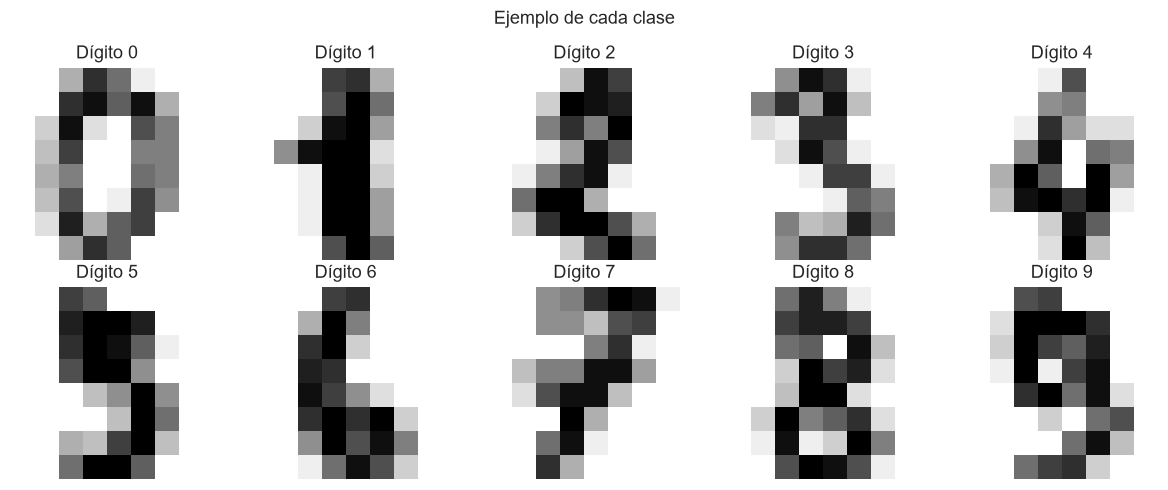

In [2]:
datos = load_digits()
NOMBRES_VARIABLES = [f"pixel_{fila}_{col}" for fila in range(8) for col in range(8)]
X = pd.DataFrame(datos.data, columns=NOMBRES_VARIABLES)
y = pd.Series(datos.target, name="digit")
CLASES = np.asarray(datos.target_names)
NOMBRES_CLASES = [str(c) for c in CLASES]

print("Dimensiones de X:", X.shape)
print("Clases:", CLASES.tolist())
print("Rango de intensidades:", X.to_numpy().min(), "a", X.to_numpy().max())
print("Valores faltantes:", int(X.isna().sum().sum()))
print("Columnas constantes:", X.columns[X.nunique() == 1].tolist())
print("Imágenes repetidas en el dataset:", int(X.duplicated().sum()))
assert not X.isna().any().any()
assert X.shape[1] == 64 and y.nunique() == 10

display(X.head())
distribucion = y.value_counts().sort_index().rename("muestras").to_frame()
distribucion["porcentaje"] = 100 * distribucion["muestras"] / len(y)
display(distribucion.round(2))

fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for clase, ax in zip(CLASES, axes.flat):
    ejemplo = np.flatnonzero(y.to_numpy() == clase)[0]
    ax.imshow(datos.images[ejemplo], cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"Dígito {clase}")
    ax.axis("off")
plt.suptitle("Ejemplo de cada clase")
plt.tight_layout()
plt.show()


## 3. Particiones comunes y preprocesamiento

Primero se reserva un **20% de prueba**. El 80% restante se divide en entrenamiento
y validación: aproximadamente **64% / 16% / 20%** del total. Se estratifica por clase
y se conservan los mismos índices para el árbol, las dos redes y los baselines.

La validación se usa para elegir profundidad, detener la red y seleccionar la
regularización. **Prueba no participa en esas decisiones.** Los modelos finales no
se reajustan con validación para mantener exactamente el mismo entrenamiento.

| Modelo | Preprocesamiento | Justificación |
| --- | --- | --- |
| Árbol | Intensidades originales | Decide mediante umbrales; no necesita estandarización |
| Red neuronal | `StandardScaler`, ajustado solo con train | Centrar y escalar facilita la optimización de sus pesos |

No se necesita imputación ni codificación categórica. Se conservan los píxeles
constantes: `StandardScaler` los maneja y mantener las 64 posiciones permite
interpretar las importancias como una imagen de 8 × 8. El escalador no observa
validación ni prueba durante su ajuste. La red no requiere matemáticamente esta
transformación para funcionar, pero centrar y escalar las distribuciones de los
píxeles suele facilitar el descenso por gradiente. El árbol puede usar sus umbrales
directamente en las intensidades originales.

**Train** ajusta pesos y reglas; **validación** elige profundidad, regularización
y época; **test** estima el resultado de los modelos ya seleccionados. Calcular
métricas de test al final no es entrenar con test, siempre que no se reutilicen
para ajustar el experimento.


,partición,muestras,porcentaje
0,Entrenamiento,1149,63.94
1,Validación,288,16.03
2,Prueba,360,20.03


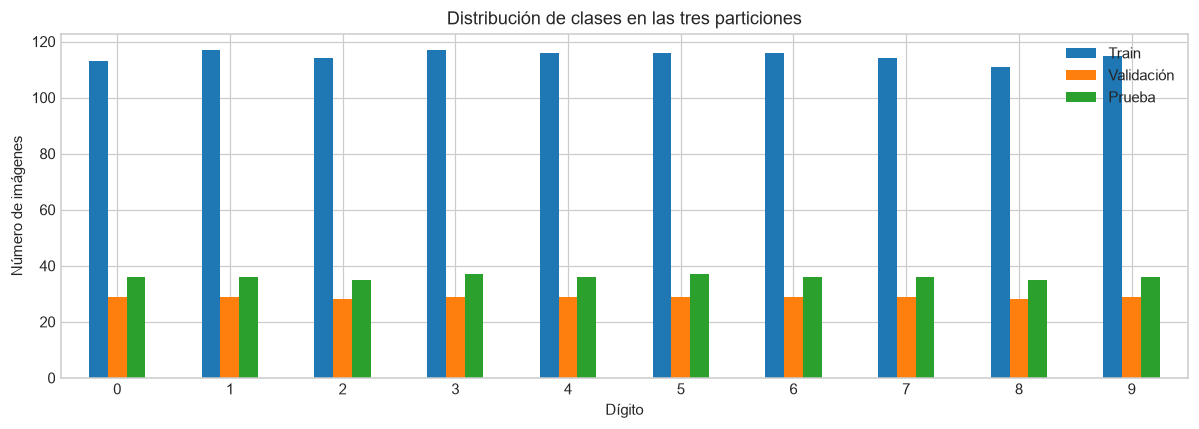

Baseline de clase mayoritaria, accuracy de validación: 0.1007
Árbol con un solo píxel, accuracy de validación: 0.2431


In [3]:
indices = np.arange(len(X))
idx_desarrollo, idx_test = train_test_split(
    indices, test_size=0.20, stratify=y, random_state=SEMILLA,
)
idx_train, idx_val = train_test_split(
    idx_desarrollo, test_size=0.20, stratify=y.iloc[idx_desarrollo], random_state=SEMILLA,
)
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test)
            or set(idx_val) & set(idx_test))
assert len(idx_train) + len(idx_val) + len(idx_test) == len(X)

X_train, X_val, X_test = X.iloc[idx_train], X.iloc[idx_val], X.iloc[idx_test]
y_train, y_val, y_test = y.iloc[idx_train], y.iloc[idx_val], y.iloc[idx_test]

scaler = StandardScaler()
X_train_nn = scaler.fit_transform(X_train)
X_val_nn = scaler.transform(X_val)
X_test_nn = scaler.transform(X_test)
assert np.allclose(scaler.mean_, X_train.mean().to_numpy())

particiones = pd.DataFrame({
    "partición": ["Entrenamiento", "Validación", "Prueba"],
    "muestras": [len(idx_train), len(idx_val), len(idx_test)],
})
particiones["porcentaje"] = 100 * particiones["muestras"] / len(X)
display(particiones.round(2))

conteos = pd.DataFrame({
    "Train": y_train.value_counts(), "Validación": y_val.value_counts(),
    "Prueba": y_test.value_counts(),
}).sort_index()
conteos.plot.bar(figsize=(11, 4), rot=0)
plt.title("Distribución de clases en las tres particiones")
plt.xlabel("Dígito")
plt.ylabel("Número de imágenes")
plt.tight_layout()
plt.show()

baseline_mayoria = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pixel_unico = ["pixel_3_3"]  # Posición fijada antes de observar los resultados.
baseline_pixel = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA)
baseline_pixel.fit(X_train[pixel_unico], y_train)
print(f"Baseline de clase mayoritaria, accuracy de validación: {baseline_mayoria.score(X_val, y_val):.4f}")
print(f"Árbol con un solo píxel, accuracy de validación: {baseline_pixel.score(X_val[pixel_unico], y_val):.4f}")


## 4. Árbol de decisión y complejidad

Se prueban profundidades máximas 2, 4, 6, 8, 12 y sin límite, manteniendo
`min_samples_leaf=2` y la misma semilla. Un árbol muy pequeño puede subajustar;
uno grande puede memorizar detalles del entrenamiento.

Se selecciona por **F1 macro de validación**. Si hay empate, se prefiere el que
tiene menos hojas. Se usa macro porque da el mismo peso a cada uno de los diez
dígitos, en lugar de ocultar clases difíciles dentro de un promedio global.


,Max depth,Profundidad real,Hojas,Nodos,Train Accuracy,Val Accuracy,Val F1 macro,Tiempo fit (s)
0,2,2,4,7,0.3229,0.3194,0.2070,0.0038
1,4,4,13,25,0.5883,0.5590,0.5120,0.0062
2,6,6,36,71,0.8216,0.7604,0.7587,0.0085
3,8,8,61,121,0.9217,0.8021,0.8018,0.0110
4,12,12,94,187,0.9695,0.8264,0.8250,0.0134
5,Sin límite,12,94,187,0.9695,0.8264,0.8250,0.0134


Profundidad elegida por validación: 12


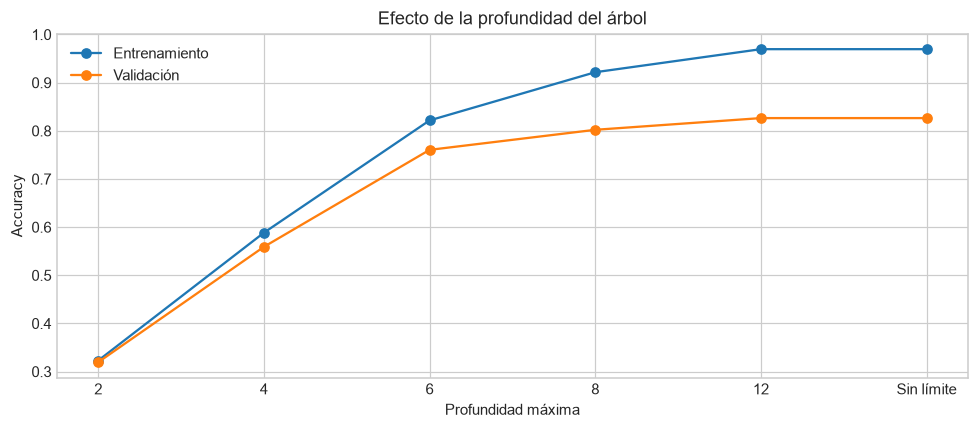

In [4]:
profundidades = [2, 4, 6, 8, 12, None]
arboles = {}
filas_arbol = []
for profundidad in profundidades:
    etiqueta = str(profundidad) if profundidad is not None else "Sin límite"
    candidato = DecisionTreeClassifier(
        max_depth=profundidad, min_samples_leaf=2, random_state=SEMILLA,
    )
    inicio = perf_counter()
    candidato.fit(X_train, y_train)
    segundos = perf_counter() - inicio
    pred_train = candidato.predict(X_train)
    pred_val = candidato.predict(X_val)
    arboles[etiqueta] = candidato
    filas_arbol.append({
        "Max depth": etiqueta, "Profundidad real": candidato.get_depth(),
        "Hojas": candidato.get_n_leaves(), "Nodos": candidato.tree_.node_count,
        "Train Accuracy": accuracy_score(y_train, pred_train),
        "Val Accuracy": accuracy_score(y_val, pred_val),
        "Val F1 macro": f1_score(y_val, pred_val, average="macro", zero_division=0),
        "Tiempo fit (s)": segundos,
    })

tabla_arboles = pd.DataFrame(filas_arbol)
display(tabla_arboles.round(4))
seleccion_arbol = tabla_arboles.sort_values(
    ["Val F1 macro", "Hojas"], ascending=[False, True], kind="stable",
).iloc[0]
arbol_final = arboles[seleccion_arbol["Max depth"]]
print("Profundidad elegida por validación:", seleccion_arbol["Max depth"])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tabla_arboles["Max depth"], tabla_arboles["Train Accuracy"], "o-", label="Entrenamiento")
ax.plot(tabla_arboles["Max depth"], tabla_arboles["Val Accuracy"], "o-", label="Validación")
ax.set(title="Efecto de la profundidad del árbol", xlabel="Profundidad máxima", ylabel="Accuracy")
ax.legend()
plt.tight_layout()
plt.show()


## 5. Diseño y entrenamiento de la red neuronal

Se usa `MLPClassifier`, una red neuronal multicapa de scikit-learn. Se distinguen:

- **Capa de entrada:** 64 valores estandarizados. Son las entradas, no una capa oculta.
- **Primera capa oculta:** 64 neuronas con ReLU.
- **Segunda capa oculta:** 32 neuronas con ReLU.
- **Capa de salida:** 10 neuronas con softmax, una por dígito.

La arquitectura **64 entradas → 64 → 32 → 10 salidas** combina píxeles mediante
dos transformaciones no lineales de tamaño moderado. Tiene
`(64+1)·64 + (64+1)·32 + (32+1)·10 = 6,570` parámetros, incluidos sesgos.
Es una elección de diseño razonable para este laboratorio, no una arquitectura óptima demostrada.

| Elemento | Función y configuración |
| --- | --- |
| ReLU | `max(0, z)`; aporta no linealidad a las capas ocultas |
| Softmax | Convierte las diez salidas en probabilidades que suman uno; no garantiza que estén bien calibradas |
| Entropía cruzada | Penaliza probabilidades bajas para la clase real, especialmente errores confiados |
| Adam | Combina estimaciones de primer y segundo momento del gradiente; tasa inicial 0.001 |
| L2 | Penaliza pesos grandes; se comparan `alpha=0.0001` y `alpha=0.01` |
| Minibatch | 64 imágenes |
| Presupuesto máximo | 250 épocas, sin aumentarlo para favorecer resultados |
| Parada externa | Paciencia 20 y mejora mínima de validación 0.0001 |

Una llamada a `partial_fit` procesa una época y conserva Adam y sus momentos.
No se sustituye por llamadas repetidas a `fit`, que podrían reiniciar el entrenamiento.
Cada red tiene su propio generador de la misma semilla, para comenzar de forma comparable.
El contador de épocas es el bucle explícito; no se usa `n_iter_` como contador acumulado.

**Early stopping:** se mantienen dos referencias. El mínimo absoluto de pérdida
de validación decide qué red se guarda. La referencia de paciencia solo se actualiza
cuando la mejora supera 0.0001; si pasan 20 épocas sin una mejora suficiente, termina
el bucle. Varias mejoras pequeñas pueden acumularse hasta superar esa referencia.
Al finalizar, por paciencia o por presupuesto, se restaura el mínimo absoluto guardado.

La restauración manual conserva nuestra misma validación explícita; no se activa
`early_stopping=True` dentro de `MLPClassifier`, que crearía otra división interna
y no es compatible con este uso de `partial_fit`.

Las curvas muestran entropía cruzada **sin L2**, calculada después de cada época,
para comparar train y validación con la misma definición. El objetivo interno de
entrenamiento sí incluye L2. El test no se evalúa durante este proceso.

Documentación: [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).


In [5]:
ARQUITECTURA = (64, 32)
MAX_EPOCAS = 250
PACIENCIA = 20
MEJORA_MINIMA = 1e-4

def entrenar_red(alpha):
    red = MLPClassifier(
        hidden_layer_sizes=ARQUITECTURA, activation="relu", solver="adam",
        alpha=alpha, batch_size=64, learning_rate_init=0.001,
        random_state=np.random.RandomState(SEMILLA), shuffle=True,
        early_stopping=False,
    )
    historial = []
    mejor_perdida = np.inf
    referencia_paciencia = np.inf
    mejor_red = None
    mejor_epoca = 0
    sin_mejora = 0
    inicio = perf_counter()

    with threadpool_limits(limits=2):
        for epoca in range(1, MAX_EPOCAS + 1):
            red.partial_fit(X_train_nn, y_train, classes=CLASES)
            proba_train = red.predict_proba(X_train_nn)
            proba_val = red.predict_proba(X_val_nn)
            perdida_train = log_loss(y_train, proba_train, labels=CLASES)
            perdida_val = log_loss(y_val, proba_val, labels=CLASES)
            historial.append({
                "epoch": epoca, "train_loss": perdida_train, "val_loss": perdida_val,
                "train_accuracy": accuracy_score(y_train, red.classes_[proba_train.argmax(axis=1)]),
                "val_accuracy": accuracy_score(y_val, red.classes_[proba_val.argmax(axis=1)]),
            })

            # Guardar el mínimo absoluto para restaurar sus pesos.
            if perdida_val < mejor_perdida:
                mejor_perdida = perdida_val
                mejor_red = copy.deepcopy(red)
                mejor_epoca = epoca
            # Una mejora suficiente reinicia la paciencia, sin cambiar el criterio de guardado.
            if perdida_val < referencia_paciencia - MEJORA_MINIMA:
                referencia_paciencia = perdida_val
                sin_mejora = 0
            else:
                sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                break

    segundos = perf_counter() - inicio
    historial = pd.DataFrame(historial)
    assert mejor_red is not None and np.isfinite(historial[["train_loss", "val_loss"]]).all().all()
    return {
        "modelo": mejor_red, "historial": historial, "alpha": alpha,
        "mejor_epoca": mejor_epoca, "epocas_ejecutadas": len(historial),
        "mejor_val_loss": mejor_perdida, "segundos": segundos,
        "motivo_parada": "paciencia" if sin_mejora >= PACIENCIA else "presupuesto de épocas",
        "paciencia_final": sin_mejora,
        "parametros": sum(w.size for w in mejor_red.coefs_) + sum(b.size for b in mejor_red.intercepts_),
    }

def graficar_aprendizaje(resultado, titulo):
    historial = resultado["historial"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for columna, etiqueta in (("train_loss", "Train"), ("val_loss", "Validación")):
        axes[0].plot(historial["epoch"], historial[columna], label=etiqueta)
    for columna, etiqueta in (("train_accuracy", "Train"), ("val_accuracy", "Validación")):
        axes[1].plot(historial["epoch"], historial[columna], label=etiqueta)
    for ax in axes:
        ax.axvline(resultado["mejor_epoca"], color="black", linestyle="--", alpha=0.5,
                   label=f"Modelo restaurado: época {resultado['mejor_epoca']}")
        if resultado["mejor_epoca"] != resultado["epocas_ejecutadas"]:
            ax.axvline(resultado["epocas_ejecutadas"], color="gray", linestyle=":",
                       label=f"Fin: época {resultado['epocas_ejecutadas']}")
        ax.set_xlabel("Época")
        ax.legend(fontsize=8)
    axes[0].set(title="Entropía cruzada", ylabel="Pérdida")
    axes[1].set(title="Accuracy", ylabel="Proporción de aciertos")
    fig.suptitle(f"{titulo} | Fin por {resultado['motivo_parada']}")
    plt.tight_layout()
    plt.show()


Arquitectura: (64, 64, 32, 10)
Activación de salida: softmax
Parámetros entrenables: 6570
Épocas ejecutadas: 60
Mejor época, restaurada: 40
Motivo de finalización: paciencia
Contador de paciencia al finalizar: 20
Menor pérdida de validación: 0.1773
Tiempo de entrenamiento y seguimiento: 0.80 s


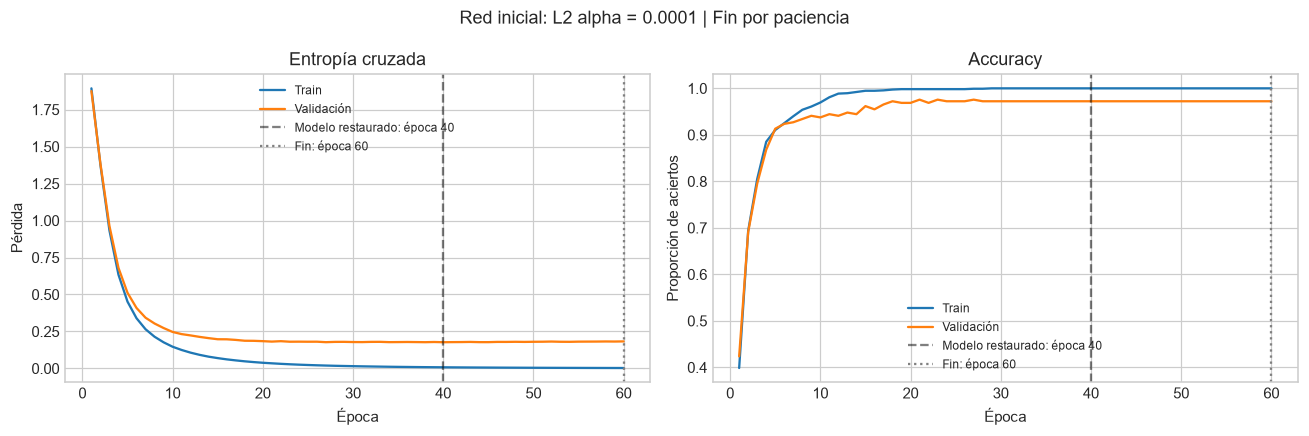

In [6]:
red_base = entrenar_red(alpha=1e-4)
print("Arquitectura:", (64, *ARQUITECTURA, 10))
print("Activación de salida:", red_base["modelo"].out_activation_)
print("Parámetros entrenables:", red_base["parametros"])
print("Épocas ejecutadas:", red_base["epocas_ejecutadas"])
print("Mejor época, restaurada:", red_base["mejor_epoca"])
print("Motivo de finalización:", red_base["motivo_parada"])
print("Contador de paciencia al finalizar:", red_base["paciencia_final"])
print(f"Menor pérdida de validación: {red_base['mejor_val_loss']:.4f}")
print(f"Tiempo de entrenamiento y seguimiento: {red_base['segundos']:.2f} s")
graficar_aprendizaje(red_base, "Red inicial: L2 alpha = 0.0001")


## 6. Exploración adicional: aumentar la regularización L2

El único **hiperparámetro configurado** que cambia es `alpha`: de 0.0001 a 0.01
(100 veces mayor). Se conservan arquitectura, inicialización, particiones,
preprocesamiento, Adam, minibatch y regla de early stopping.

La regla de parada es igual, pero su **duración efectiva puede ser distinta**.
Se comparan dos procedimientos de L2 + early stopping, no dos redes entrenadas
necesariamente el mismo número de épocas. Por ello, la diferencia final de test
no permite aislar cuánto proviene de L2 y cuánto de la duración seleccionada.

La red final se elige por su menor pérdida de validación. Para complementar la
comparación sin entrenar más modelos, se comparan abajo las trayectorias existentes
a una misma época, usando exclusivamente train y validación.


,Experimento,Alpha,Parámetros,Épocas ejecutadas,Mejor época,Motivo de fin,Val Loss,Val Accuracy
0,Base (L2=0.0001),0.0001,6570,60,40,paciencia,0.1773,0.9722
1,L2 mayor (L2=0.01),0.0100,6570,250,250,presupuesto de épocas,0.0582,0.9861


Red elegida únicamente por validación: L2 mayor (L2=0.01)


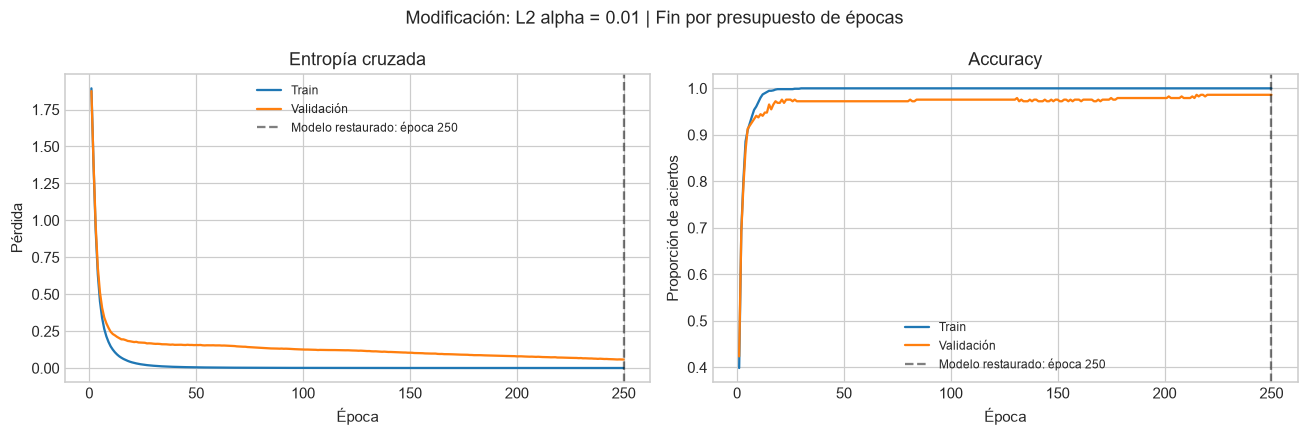

In [7]:
red_regularizada = entrenar_red(alpha=1e-2)
experimentos_red = {"Base (L2=0.0001)": red_base, "L2 mayor (L2=0.01)": red_regularizada}

tabla_validacion_red = pd.DataFrame([
    {"Experimento": nombre, "Alpha": r["alpha"], "Parámetros": r["parametros"],
     "Épocas ejecutadas": r["epocas_ejecutadas"], "Mejor época": r["mejor_epoca"],
     "Motivo de fin": r["motivo_parada"],
     "Val Loss": r["mejor_val_loss"],
     "Val Accuracy": r["modelo"].score(X_val_nn, y_val)}
    for nombre, r in experimentos_red.items()
])
display(tabla_validacion_red.round(4))
nombre_red_final = min(experimentos_red, key=lambda nombre: experimentos_red[nombre]["mejor_val_loss"])
resultado_red_final = experimentos_red[nombre_red_final]
red_final = resultado_red_final["modelo"]
print("Red elegida únicamente por validación:", nombre_red_final)
graficar_aprendizaje(red_regularizada, "Modificación: L2 alpha = 0.01")


### 6.1. Control descriptivo con el mismo número de épocas

Se usa la última época disponible en **ambos** historiales: el mínimo de sus
duraciones. Se fija así a partir del entrenamiento y la validación, sin consultar
test. A igual época, ambas redes han procesado el mismo número de minibatches,
con inicialización y secuencia aleatoria comparables.

Los valores corresponden al estado de **esa época**, antes de restaurar sus
respectivos mejores modelos; no deben confundirse con las métricas finales de test.
Se comparan pérdidas predictivas sin L2 para usar la misma definición.
Este control describe el efecto de `alpha` a igual duración en esta ejecución;
no demuestra un efecto universal ni significación estadística. No se calcula test
para escoger una época a partir de este análisis.


,Experimento,Época común,Train Loss,Val Loss,Train Accuracy,Val Accuracy
0,Base (L2=0.0001),60,0.0030,0.1829,1.0,0.9722
1,L2 mayor (L2=0.01),60,0.0036,0.1538,1.0,0.9722


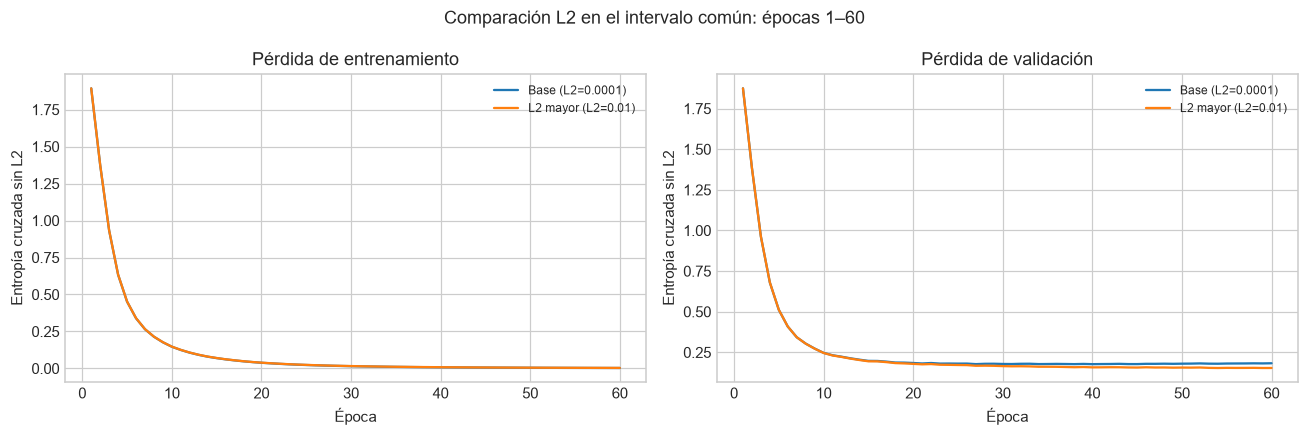

A la misma época **60**, el cambio de pérdida de validación (L2 mayor − base) es **-0.0291**. Es una comparación distinta de la que utiliza los mejores modelos restaurados.

In [8]:
EPOCA_COMUN = min(r["epocas_ejecutadas"] for r in experimentos_red.values())
filas_control = []
for nombre, resultado in experimentos_red.items():
    fila = resultado["historial"].set_index("epoch").loc[EPOCA_COMUN]
    filas_control.append({
        "Experimento": nombre, "Época común": EPOCA_COMUN,
        "Train Loss": fila["train_loss"], "Val Loss": fila["val_loss"],
        "Train Accuracy": fila["train_accuracy"], "Val Accuracy": fila["val_accuracy"],
    })
tabla_control_l2 = pd.DataFrame(filas_control)
display(tabla_control_l2.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nombre, resultado in experimentos_red.items():
    tramo = resultado["historial"].query("epoch <= @EPOCA_COMUN")
    axes[0].plot(tramo["epoch"], tramo["train_loss"], label=nombre)
    axes[1].plot(tramo["epoch"], tramo["val_loss"], label=nombre)
for ax, titulo in zip(axes, ["Pérdida de entrenamiento", "Pérdida de validación"]):
    ax.set(title=titulo, xlabel="Época", ylabel="Entropía cruzada sin L2")
    ax.legend(fontsize=8)
fig.suptitle(f"Comparación L2 en el intervalo común: épocas 1–{EPOCA_COMUN}")
plt.tight_layout()
plt.show()

delta_control_val = tabla_control_l2.iloc[1]["Val Loss"] - tabla_control_l2.iloc[0]["Val Loss"]
display(Markdown(
    f"A la misma época **{EPOCA_COMUN}**, el cambio de pérdida de validación "
    f"(L2 mayor − base) es **{delta_control_val:+.4f}**. "
    "Es una comparación distinta de la que utiliza los mejores modelos restaurados."
))


## 7. Evaluación final y tabla comparativa

La profundidad del árbol y la variante de red ya están elegidas. Ahora se abre
prueba para calcular **Accuracy, Precision macro, Recall macro y F1 macro**.
`Train Score` se define como accuracy sobre las mismas filas de entrenamiento.
La tabla principal reproduce exactamente las columnas solicitadas en el PDF.
La brecha train-test se calcula aparte para el análisis, no como otra métrica exigida.

Se usan las diez clases explícitamente y `zero_division=0` si un modelo no predice
alguna clase. Los promedios macro asignan igual peso a cada dígito. Se muestran
también los resultados por clase para no depender solo del promedio.


In [9]:
def evaluar_modelo(nombre, modelo, entradas_train, entradas_test):
    pred_train = modelo.predict(entradas_train)
    pred_test = modelo.predict(entradas_test)
    train_score = accuracy_score(y_train, pred_train)
    test_score = accuracy_score(y_test, pred_test)
    fila = {
        "Model": nombre, "Train Score": train_score, "Accuracy": test_score,
        "Precision": precision_score(y_test, pred_test, labels=CLASES, average="macro", zero_division=0),
        "Recall": recall_score(y_test, pred_test, labels=CLASES, average="macro", zero_division=0),
        "F1-score": f1_score(y_test, pred_test, labels=CLASES, average="macro", zero_division=0),
        "Gap train-test": train_score - test_score,
    }
    return fila, pred_test

fila_arbol, pred_test_arbol = evaluar_modelo("Decision Tree", arbol_final, X_train, X_test)
fila_red, pred_test_red = evaluar_modelo("Neural Network", red_final, X_train_nn, X_test_nn)
COLUMNAS_PDF = ["Train Score", "Accuracy", "Precision", "Recall", "F1-score"]
comparacion = pd.DataFrame([fila_arbol, fila_red]).set_index("Model")[COLUMNAS_PDF]
display(comparacion.round(4))

for nombre, predicciones in (("Decision Tree", pred_test_arbol), ("Neural Network", pred_test_red)):
    print("\n", nombre)
    informe = classification_report(
        y_test, predicciones, labels=CLASES, target_names=NOMBRES_CLASES,
        output_dict=True, zero_division=0,
    )
    informe_por_clase = {clase: valores for clase, valores in informe.items()
                         if isinstance(valores, dict)}
    display(pd.DataFrame(informe_por_clase).T.round(4))

metricas_principales = comparacion[["Train Score", "Accuracy", "Precision", "Recall", "F1-score"]]
assert np.isfinite(metricas_principales.to_numpy()).all()
assert ((metricas_principales >= 0) & (metricas_principales <= 1)).all().all()
assert np.allclose(red_final.predict_proba(X_test_nn).sum(axis=1), 1)


,Train Score,Accuracy,Precision,Recall,F1-score
Model,,,,,
Decision Tree,0.9695,0.8167,0.8190,0.8158,0.8144
Neural Network,1.0000,0.9778,0.9784,0.9775,0.9776



 Decision Tree


,precision,recall,f1-score,support
0,0.9189,0.9444,0.9315,36.0
1,0.7368,0.7778,0.7568,36.0
2,0.6977,0.8571,0.7692,35.0
3,0.7619,0.8649,0.8101,37.0
4,0.8824,0.8333,0.8571,36.0
5,0.8919,0.8919,0.8919,37.0
6,0.9143,0.8889,0.9014,36.0
7,0.8286,0.8056,0.8169,36.0
8,0.7692,0.5714,0.6557,35.0
9,0.7879,0.7222,0.7536,36.0



 Neural Network


,precision,recall,f1-score,support
0,1.0000,1.0000,1.0000,36.0
1,0.8947,0.9444,0.9189,36.0
2,0.9722,1.0000,0.9859,35.0
3,1.0000,1.0000,1.0000,37.0
4,1.0000,1.0000,1.0000,36.0
5,1.0000,1.0000,1.0000,37.0
6,1.0000,0.9722,0.9859,36.0
7,0.9474,1.0000,0.9730,36.0
8,0.9697,0.9143,0.9412,35.0
9,1.0000,0.9444,0.9714,36.0


## 8. Matrices de confusión y ejemplos de error

Las filas corresponden a clases **reales** y las columnas a **predicciones**.
La diagonal contiene los aciertos; los valores fuera de ella permiten identificar
qué dígitos se confunden. Ambas matrices usan exactamente las mismas imágenes de
prueba y el mismo orden de clases. Se muestran conteos, no porcentajes.


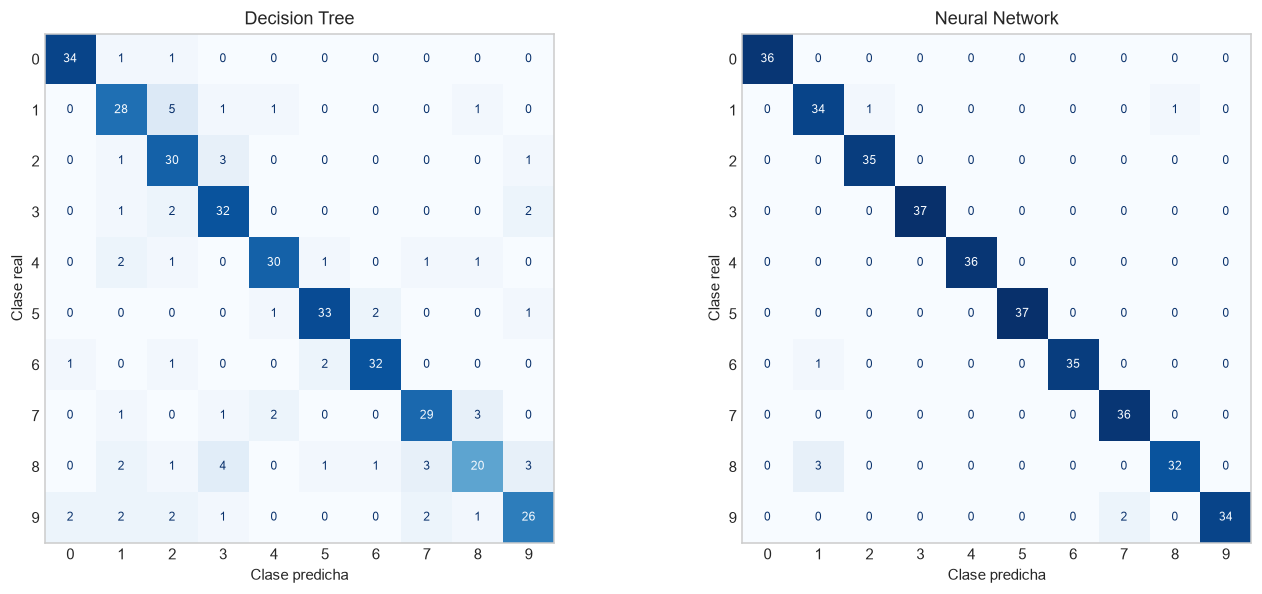

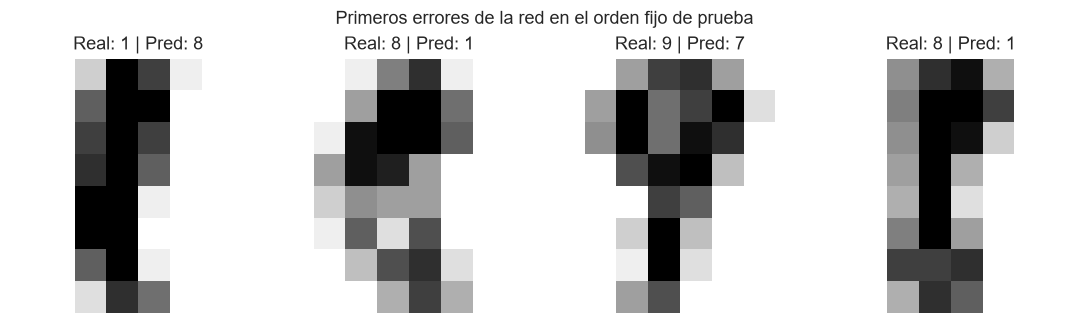

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, nombre, predicciones in (
    (axes[0], "Decision Tree", pred_test_arbol),
    (axes[1], "Neural Network", pred_test_red),
):
    matriz = confusion_matrix(y_test, predicciones, labels=CLASES)
    assert matriz.sum() == len(y_test)
    ConfusionMatrixDisplay(matriz, display_labels=CLASES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": int(y_test.value_counts().max())},
        text_kw={"fontsize": 8},
    )
    ax.set_title(nombre)
    ax.grid(False)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

errores = np.flatnonzero(y_test.to_numpy() != pred_test_red)
if len(errores):
    fig, axes = plt.subplots(1, min(4, len(errores)), figsize=(10, 3), squeeze=False)
    for ax, posicion in zip(axes.flat, errores[:4]):
        ax.imshow(X_test.iloc[posicion].to_numpy().reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
        ax.set_title(f"Real: {y_test.iloc[posicion]} | Pred: {pred_test_red[posicion]}")
        ax.axis("off")
    fig.suptitle("Primeros errores de la red en el orden fijo de prueba")
    plt.tight_layout()
    plt.show()
else:
    print("No se observaron errores de la red en esta partición de prueba.")


## 9. Efecto de la modificación en entrenamiento y prueba

Se reportan ambas variantes para cumplir la exploración solicitada. Esta tabla
no cambia la selección previa por validación: el test se usa para describir el
resultado final, no para reajustar hiperparámetros. Cada red se evalúa tras
restaurar su mejor época de validación, que puede ser distinta entre variantes.


In [11]:
filas_exploracion = []
for nombre, resultado in experimentos_red.items():
    fila, _ = evaluar_modelo(nombre, resultado["modelo"], X_train_nn, X_test_nn)
    fila.update({"Alpha": resultado["alpha"], "Val Loss": resultado["mejor_val_loss"],
                 "Mejor época": resultado["mejor_epoca"]})
    filas_exploracion.append(fila)
comparacion_l2 = pd.DataFrame(filas_exploracion).set_index("Model")
display(comparacion_l2.round(4))

base = comparacion_l2.loc["Base (L2=0.0001)"]
regularizada = comparacion_l2.loc["L2 mayor (L2=0.01)"]
delta_train = regularizada["Train Score"] - base["Train Score"]
delta_test = regularizada["Accuracy"] - base["Accuracy"]
delta_f1 = regularizada["F1-score"] - base["F1-score"]
delta_val_loss = regularizada["Val Loss"] - base["Val Loss"]
display(Markdown(
    f"**Comparación de procedimientos L2 + early stopping:** base restaurada en la época "
    f"{red_base['mejor_epoca']} y L2 mayor restaurada en la época {red_regularizada['mejor_epoca']}. "
    f"La accuracy de entrenamiento cambió **{delta_train * 100:+.2f} puntos porcentuales**, "
    f"la de prueba **{delta_test * 100:+.2f} puntos** y el F1 macro de prueba **{delta_f1:+.4f}**. "
    f"La pérdida de validación cambió **{delta_val_loss:+.4f}** (menor es mejor). "
    f"La selección por validación fue **{nombre_red_final}**. "
    "La diferencia final combina regularización y duración efectiva: no se atribuye exclusivamente a L2. "
    f"El control a igual duración, {EPOCA_COMUN} épocas, está en la sección 6.1 y usa solo train/validación."
))


,Train Score,Accuracy,Precision,Recall,F1-score,Gap train-test,Alpha,Val Loss,Mejor época
Model,,,,,,,,,
Base (L2=0.0001),1.0,0.9611,0.9617,0.9609,0.9609,0.0389,0.0001,0.1773,40
L2 mayor (L2=0.01),1.0,0.9778,0.9784,0.9775,0.9776,0.0222,0.0100,0.0582,250


**Comparación de procedimientos L2 + early stopping:** base restaurada en la época 40 y L2 mayor restaurada en la época 250. La accuracy de entrenamiento cambió **+0.00 puntos porcentuales**, la de prueba **+1.67 puntos** y el F1 macro de prueba **+0.0167**. La pérdida de validación cambió **-0.1191** (menor es mejor). La selección por validación fue **L2 mayor (L2=0.01)**. La diferencia final combina regularización y duración efectiva: no se atribuye exclusivamente a L2. El control a igual duración, 60 épocas, está en la sección 6.1 y usa solo train/validación.

## 10. Interpretabilidad y complejidad

**¿Qué modelo es más interpretable?** El árbol expone reglas del tipo
`pixel_fila_columna <= umbral`, con una ruta explícita hasta la clase. La red
combina intensidades mediante miles de pesos y activaciones; mirar un peso por
separado no explica toda la predicción.

**¿Qué ocurre al aumentar complejidad?** Un árbol más profundo tiene más reglas,
puede ajustarse mejor a train y es más difícil de leer. Si validación deja de
mejorar mientras train aumenta, hay indicios de sobreajuste. Una red más ancha
o profunda puede representar patrones más complejos, pero aumenta parámetros,
costo y riesgo de sobreajuste. Más capacidad no garantiza generalización.

Se muestran los primeros niveles del árbol y sus importancias de píxeles. Las
importancias se basan en reducción de impureza; **no son efectos causales** y
pueden repartirse entre píxeles correlacionados. El dibujo está truncado para
poder leerlo; no representa todas las reglas del árbol seleccionado.


Profundidad real del árbol: 12
Hojas: 94
Nodos: 187
Parámetros de la red: 6570


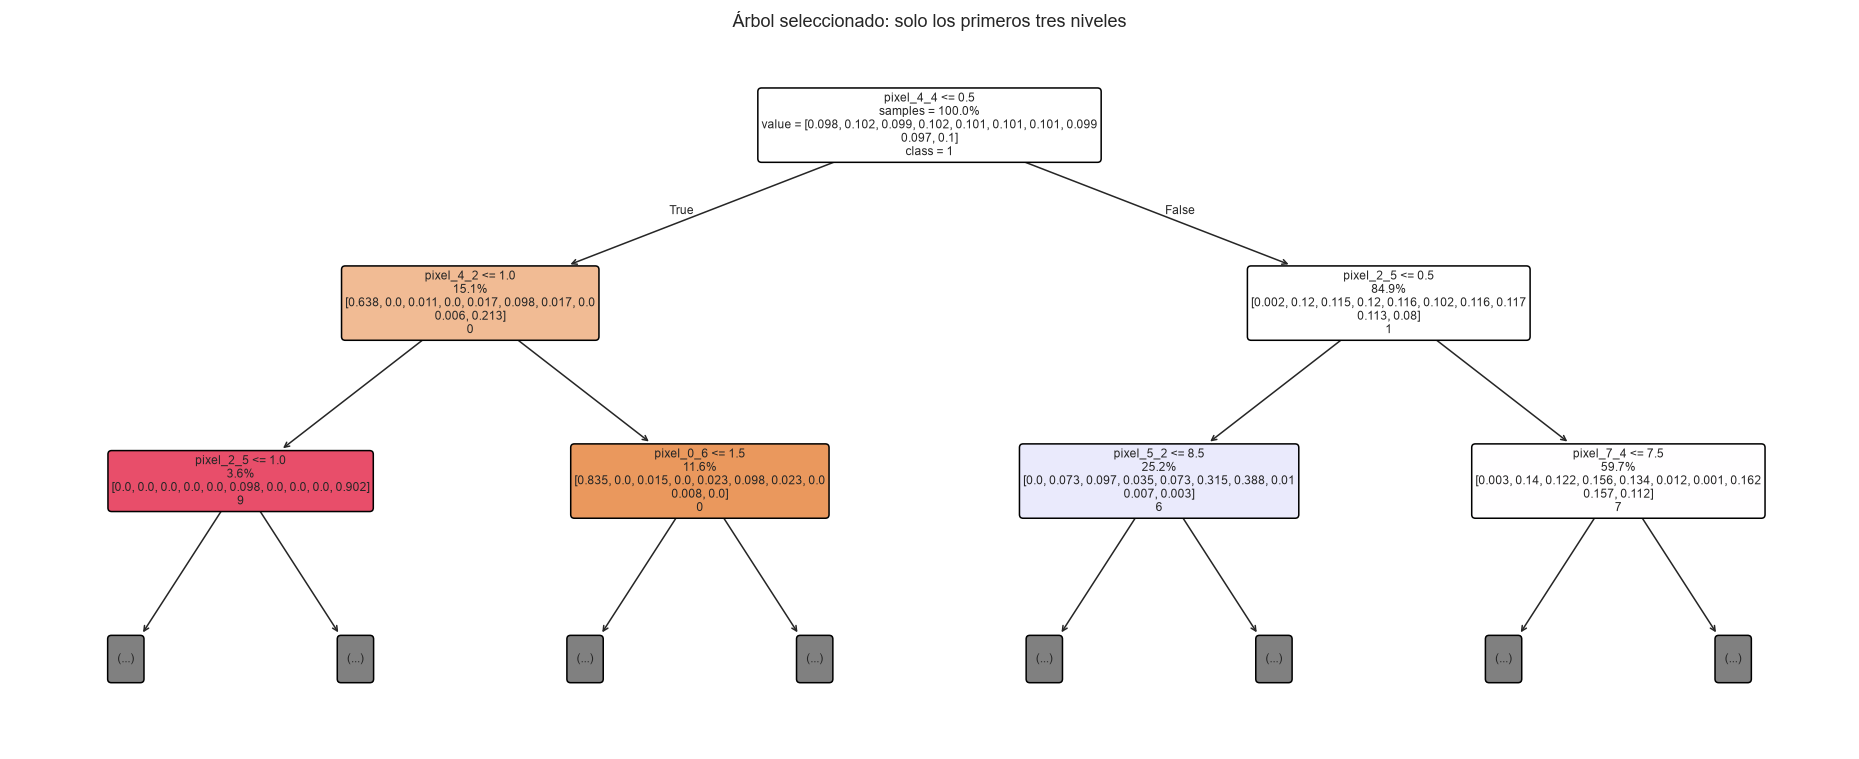

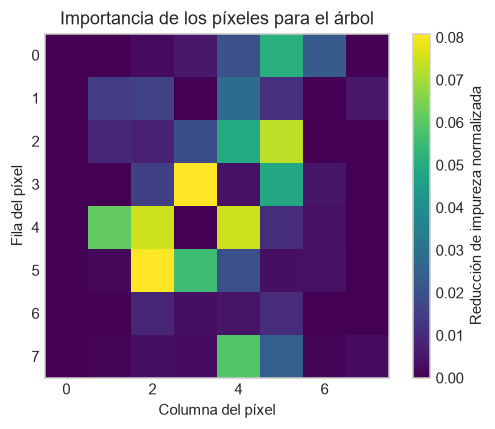


Ruta del árbol para la primera imagen de prueba:
pixel_4_4 = 0.0 <= 0.50
pixel_4_2 = 4.0 > 1.00
pixel_0_6 = 3.0 > 1.50
Clase real: 5 | Predicción: 5


In [12]:
print("Profundidad real del árbol:", arbol_final.get_depth())
print("Hojas:", arbol_final.get_n_leaves())
print("Nodos:", arbol_final.tree_.node_count)
print("Parámetros de la red:", resultado_red_final["parametros"])

fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(
    arbol_final, feature_names=NOMBRES_VARIABLES, class_names=NOMBRES_CLASES,
    max_depth=2, filled=True, rounded=True, impurity=False, proportion=True,
    label="root", fontsize=8, ax=ax,
)
ax.set_title("Árbol seleccionado: solo los primeros tres niveles")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
imagen_importancia = ax.imshow(arbol_final.feature_importances_.reshape(8, 8), cmap="viridis")
ax.grid(False)
ax.set(title="Importancia de los píxeles para el árbol", xlabel="Columna del píxel", ylabel="Fila del píxel")
fig.colorbar(imagen_importancia, ax=ax, label="Reducción de impureza normalizada")
plt.tight_layout()
plt.show()

# Seguir una ruta real de decisión: primera observación del test, sin escoger por resultado.
ejemplo = X_test.iloc[[0]]
ruta = arbol_final.decision_path(ejemplo).indices
reglas = []
for nodo in ruta:
    variable = arbol_final.tree_.feature[nodo]
    if variable >= 0:
        valor = float(ejemplo.iloc[0, variable])
        umbral = float(arbol_final.tree_.threshold[nodo])
        operador = "<=" if valor <= umbral else ">"
        reglas.append(f"{NOMBRES_VARIABLES[variable]} = {valor:.1f} {operador} {umbral:.2f}")
print("\nRuta del árbol para la primera imagen de prueba:")
print("\n".join(reglas))
print("Clase real:", y_test.iloc[0], "| Predicción:", arbol_final.predict(ejemplo)[0])


## 11. Conclusiones basadas en los resultados

Las siguientes conclusiones se generan a partir de la ejecución. La brecha
train-test es una señal descriptiva, no una prueba estadística de sobreajuste.
Una sola partición no establece que un algoritmo sea siempre superior a otro.


In [13]:
mejor_test = comparacion["F1-score"].idxmax()
brecha_arbol = fila_arbol["Gap train-test"]
brecha_red = fila_red["Gap train-test"]
arbol_simple = tabla_arboles.iloc[0]
arbol_complejo = tabla_arboles.iloc[-1]

conclusion = f'''### Resultados observados

- **Dataset y comparación justa:** se utilizaron {len(X_train)} imágenes para entrenar,
  {len(X_val)} para validar y {len(X_test)} para probar, con los mismos índices en todos los modelos.
- **Árbol:** se seleccionó max_depth = **{seleccion_arbol['Max depth']}** por F1 macro de validación.
  Su accuracy pasó de **{comparacion.loc['Decision Tree', 'Train Score']:.4f}** en train a
  **{comparacion.loc['Decision Tree', 'Accuracy']:.4f}** en test; brecha **{brecha_arbol:.4f}**.
- **Red neuronal:** se seleccionó **{nombre_red_final}**, con arquitectura 64-64-32-10,
  **{resultado_red_final['parametros']:,} parámetros**, **{resultado_red_final['epocas_ejecutadas']} épocas ejecutadas**
  y restauración de la época **{resultado_red_final['mejor_epoca']}**.
  Su accuracy fue **{comparacion.loc['Neural Network', 'Train Score']:.4f}** en train y
  **{comparacion.loc['Neural Network', 'Accuracy']:.4f}** en test; brecha **{brecha_red:.4f}**.
- **Mejor F1 macro en esta prueba:** **{mejor_test}**, con **{comparacion.loc[mejor_test, 'F1-score']:.4f}**.
  Esta observación describe esta partición; no se usó para elegir hiperparámetros.
- **Complejidad del árbol:** el modelo de profundidad 2 obtuvo accuracy train/val de
  **{arbol_simple['Train Accuracy']:.4f}/{arbol_simple['Val Accuracy']:.4f}**;
  el árbol sin límite obtuvo **{arbol_complejo['Train Accuracy']:.4f}/{arbol_complejo['Val Accuracy']:.4f}**.
  La curva permite distinguir el costo de una capacidad insuficiente y la posible brecha al crecer.
- **L2 + early stopping:** los mejores modelos restaurados difirieron **{delta_test * 100:+.2f}
  puntos porcentuales** de accuracy de prueba y **{delta_f1:+.4f}** de F1 macro.
  Como se restauraron épocas distintas, la diferencia no aísla el efecto exclusivo de L2.
- **Control a igual duración:** a la época **{EPOCA_COMUN}**, la variación de pérdida de
  validación fue **{delta_control_val:+.4f}**. Usa únicamente las trayectorias comunes de train/validación.
- **Motivo de finalización:** la red base terminó por **{red_base['motivo_parada']}**
  tras **{red_base['epocas_ejecutadas']} épocas**, y la red con mayor L2 por
  **{red_regularizada['motivo_parada']}** tras **{red_regularizada['epocas_ejecutadas']}**.
  Un mínimo en la última época disponible no demuestra convergencia ni obliga a aumentar el presupuesto.

### Interpretación y elección

El árbol es más transparente porque permite seguir una secuencia de umbrales.
Un árbol muy grande también puede ser difícil de comprender completo, por lo que
la interpretabilidad depende de su tamaño. La red requiere interpretar el efecto
conjunto de sus capas y pesos, aunque puede capturar mejor patrones distribuidos.

Si ambos rindieran de forma similar, elegiría según la necesidad de explicar
decisiones, el tiempo de entrenamiento e inferencia, la memoria, el mantenimiento
y las consecuencias de confundir ciertas clases. Para este problema de patrones
visuales, priorizaría el rendimiento observado si la aplicación permite menor
transparencia; si las reglas explícitas fueran esenciales, consideraría un árbol
compacto aun aceptando una pérdida de rendimiento.

El árbol de profundidad 2 muestra capacidad insuficiente al rendir bajo tanto
en train como en validación. Al crecer, la brecha entre ambos aumenta: son indicios
de sobreajuste, no una prueba estadística. En la red, la pérdida de validación puede
empeorar aunque la accuracy apenas cambie, porque también importa la confianza en
los errores. Obtener 100% en train no equivale a 100% fuera de muestra.

El test no interviene en el entrenamiento ni en la selección. Early stopping y L2
ayudan a controlar el ajuste, pero no garantizan eliminar el sobreajuste. Este test
ya se había reportado; la revisión no usa sus resultados para cambiar hiperparámetros
y su repetición no cuenta como nueva evidencia independiente. Una evaluación
más sólida usaría varias particiones o validación cruzada dentro del desarrollo,
manteniendo una prueba final intacta.
'''
display(Markdown(conclusion))


### Resultados observados

- **Dataset y comparación justa:** se utilizaron 1149 imágenes para entrenar,
  288 para validar y 360 para probar, con los mismos índices en todos los modelos.
- **Árbol:** se seleccionó max_depth = **12** por F1 macro de validación.
  Su accuracy pasó de **0.9695** en train a
  **0.8167** en test; brecha **0.1529**.
- **Red neuronal:** se seleccionó **L2 mayor (L2=0.01)**, con arquitectura 64-64-32-10,
  **6,570 parámetros**, **250 épocas ejecutadas**
  y restauración de la época **250**.
  Su accuracy fue **1.0000** en train y
  **0.9778** en test; brecha **0.0222**.
- **Mejor F1 macro en esta prueba:** **Neural Network**, con **0.9776**.
  Esta observación describe esta partición; no se usó para elegir hiperparámetros.
- **Complejidad del árbol:** el modelo de profundidad 2 obtuvo accuracy train/val de
  **0.3229/0.3194**;
  el árbol sin límite obtuvo **0.9695/0.8264**.
  La curva permite distinguir el costo de una capacidad insuficiente y la posible brecha al crecer.
- **L2 + early stopping:** los mejores modelos restaurados difirieron **+1.67
  puntos porcentuales** de accuracy de prueba y **+0.0167** de F1 macro.
  Como se restauraron épocas distintas, la diferencia no aísla el efecto exclusivo de L2.
- **Control a igual duración:** a la época **60**, la variación de pérdida de
  validación fue **-0.0291**. Usa únicamente las trayectorias comunes de train/validación.
- **Motivo de finalización:** la red base terminó por **paciencia**
  tras **60 épocas**, y la red con mayor L2 por
  **presupuesto de épocas** tras **250**.
  Un mínimo en la última época disponible no demuestra convergencia ni obliga a aumentar el presupuesto.

### Interpretación y elección

El árbol es más transparente porque permite seguir una secuencia de umbrales.
Un árbol muy grande también puede ser difícil de comprender completo, por lo que
la interpretabilidad depende de su tamaño. La red requiere interpretar el efecto
conjunto de sus capas y pesos, aunque puede capturar mejor patrones distribuidos.

Si ambos rindieran de forma similar, elegiría según la necesidad de explicar
decisiones, el tiempo de entrenamiento e inferencia, la memoria, el mantenimiento
y las consecuencias de confundir ciertas clases. Para este problema de patrones
visuales, priorizaría el rendimiento observado si la aplicación permite menor
transparencia; si las reglas explícitas fueran esenciales, consideraría un árbol
compacto aun aceptando una pérdida de rendimiento.

El árbol de profundidad 2 muestra capacidad insuficiente al rendir bajo tanto
en train como en validación. Al crecer, la brecha entre ambos aumenta: son indicios
de sobreajuste, no una prueba estadística. En la red, la pérdida de validación puede
empeorar aunque la accuracy apenas cambie, porque también importa la confianza en
los errores. Obtener 100% en train no equivale a 100% fuera de muestra.

El test no interviene en el entrenamiento ni en la selección. Early stopping y L2
ayudan a controlar el ajuste, pero no garantizan eliminar el sobreajuste. Este test
ya se había reportado; la revisión no usa sus resultados para cambiar hiperparámetros
y su repetición no cuenta como nueva evidencia independiente. Una evaluación
más sólida usaría varias particiones o validación cruzada dentro del desarrollo,
manteniendo una prueba final intacta.


## 12. Comprobaciones finales

Estas verificaciones comprueban coherencia de datos y resultados. El notebook
guarda las salidas al ejecutarse; no modifica ni descarga otros archivos.


In [14]:
assert np.array_equal(arbol_final.classes_, red_final.classes_)
assert len(pred_test_arbol) == len(pred_test_red) == len(y_test)
assert len(resultado_red_final["modelo"].coefs_) == 3
assert resultado_red_final["modelo"].out_activation_ == "softmax"
assert comparacion.columns.tolist() == COLUMNAS_PDF
for resultado in experimentos_red.values():
    assert resultado["historial"]["epoch"].tolist() == list(range(1, resultado["epocas_ejecutadas"] + 1))
    assert resultado["mejor_epoca"] <= resultado["epocas_ejecutadas"] <= MAX_EPOCAS
    perdida_restaurada = log_loss(y_val, resultado["modelo"].predict_proba(X_val_nn), labels=CLASES)
    assert np.isclose(perdida_restaurada, resultado["mejor_val_loss"], atol=1e-12)

print("Comprobaciones correctas:")
print("- Mismas particiones de entrenamiento, validación y prueba.")
print("- Escalador ajustado solo con entrenamiento.")
print("- Red multiclase con softmax y curvas por época.")
print("- Mejor modelo restaurado según la pérdida de validación.")
print("- Tabla con las métricas del PDF y matrices de confusión.")
print("- Comparación L2 con early stopping y control a igual duración.")
print("- Conclusiones generadas a partir de los resultados reales.")


Comprobaciones correctas:
- Mismas particiones de entrenamiento, validación y prueba.
- Escalador ajustado solo con entrenamiento.
- Red multiclase con softmax y curvas por época.
- Mejor modelo restaurado según la pérdida de validación.
- Tabla con las métricas del PDF y matrices de confusión.
- Comparación L2 con early stopping y control a igual duración.
- Conclusiones generadas a partir de los resultados reales.


## Referencias

- Enunciado proporcionado: `Lab3_AA_NN_EN.pdf`, *Comparing Decision Trees and Neural Networks*.
- [Digits en scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html).
- [Optical Recognition of Handwritten Digits en UCI](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits).
- [MLPClassifier y partial_fit](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).
- [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).
- [Precision, recall y F1](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).

XGBoost es opcional en el enunciado. Esta entrega desarrolla los dos modelos
obligatorios y la exploración adicional de regularización.
